# Transformer, one tensor at a time

A step-by-step visualisation of the NumPy Transformer in `src/numpy_transformer`, using a tiny configuration so every number fits on screen.

| setting | value |
|---|---|
| `d_model` | 8 |
| heads | 2 (so `d_k = 4`) |
| `d_ff` | 16 |
| layers | 1 encoder + 1 decoder |
| batch size | 2 |
| steps | 2 |
| epochs | 1 (2 steps x 2 rows = all 4 rows once) |

Task: **sort 5 digits**. The encoder sees the unsorted digits; the decoder is teacher-forced with `SOS + sorted digits` and must predict `sorted digits + EOS`.

Every hand-computed result is checked against the library layer with `assert np.allclose(...)`, so the notebook is a proof that the by-hand math equals the real code.

Sections: 0 setup, 1 data, 2 embedding, 3 positional encoding, 4 attention, 5 multi-head, 6 encoder layer, 7 decoder, 8 full forward data-flow, 9 loss/backward/update (2 steps).

In [1]:
import sys, pathlib
import numpy as np
import matplotlib.pyplot as plt

ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():          # allow running from notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from numpy_transformer.layers import Transformer
from numpy_transformer.sort_data import PAD_ID, SOS_ID, EOS_ID, VOCAB_SIZE
from numpy_transformer.training import (
    cross_entropy_with_label_smoothing, noam_lr, Adam, zero_grads)

np.set_printoptions(precision=3, suppress=True, linewidth=140)
plt.rcParams.update({"figure.dpi": 100, "image.cmap": "coolwarm"})

# ---- configuration ----
D_MODEL, N_HEADS, D_FF = 8, 2, 16
BATCH_SIZE, N_STEPS, N_EPOCHS = 2, 2, 1
WARMUP = 4          # the repo default is 400; with only 2 steps we use 4 so the lr is visible
EPS_LS = 0.1        # label smoothing
SEED = 0
D_K = D_MODEL // N_HEADS
TOK = {**{i: str(i) for i in range(10)}, SOS_ID: "SOS", EOS_ID: "EOS", PAD_ID: "PAD"}

def heat(M, xl=None, yl=None, title="", ax=None, fmt="{:.2f}", vmax=None, cmap=None):
    """Annotated heat map of a 2-D array."""
    M = np.asarray(M, dtype=float)
    ax = ax or plt.subplots(figsize=(max(3, 0.55 * M.shape[1] + 1), max(2, 0.5 * M.shape[0] + 1)))[1]
    v = vmax or max(abs(M).max(), 1e-9)
    ax.imshow(M, vmin=-v, vmax=v, cmap=cmap or "coolwarm", aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center", fontsize=7)
    ax.set_xticks(range(M.shape[1])); ax.set_yticks(range(M.shape[0]))
    if xl is not None: ax.set_xticklabels(xl, fontsize=8)
    if yl is not None: ax.set_yticklabels(yl, fontsize=8)
    ax.set_title(title, fontsize=9)
    return ax

def softmax(x):
    e = np.exp(x - x.max(-1, keepdims=True))
    return e / e.sum(-1, keepdims=True)

## 1. Data and batching

Your four rows come from `train_input/sort_train_preview.csv` (rows 1-4; the first CSV column is just a row id).
With `batch_size=2` and `steps=2`, step 1 takes rows 1-2 and step 2 takes rows 3-4. That is exactly one epoch. The repo's `train()` samples batches randomly, but here batches are taken in order so every row is visited once.

In [2]:
import csv
rows = list(csv.reader(open(ROOT / "train_input" / "sort_train_preview.csv")))
hdr, body = rows[0], np.array(rows[1:], dtype=int)
body = body[(body[:, 0] >= 1) & (body[:, 0] <= 4)]          # the 4 rows you gave
ENC = body[:, 1:6]       # (4, 5)  unsorted digits
DEC_IN = body[:, 6:12]   # (4, 6)  SOS + sorted
DEC_TGT = body[:, 12:18] # (4, 6)  sorted + EOS

for r in range(4):
    print(f"row {body[r,0]}: enc={ENC[r]}  dec_in={DEC_IN[r]}  dec_tgt={DEC_TGT[r]}   "
          f"-> {[TOK[t] for t in DEC_IN[r]]} => {[TOK[t] for t in DEC_TGT[r]]}")
assert (np.sort(ENC, 1) == DEC_IN[:, 1:]).all()
print("\nvocab: digits 0-9, PAD=10, SOS=11, EOS=12  (V=%d)" % VOCAB_SIZE)

BATCHES = [(ENC[s*BATCH_SIZE:(s+1)*BATCH_SIZE], DEC_IN[s*BATCH_SIZE:(s+1)*BATCH_SIZE],
            DEC_TGT[s*BATCH_SIZE:(s+1)*BATCH_SIZE]) for s in range(N_STEPS)]
print("\nstep 1 encoder batch:\n", BATCHES[0][0], "\nstep 2 encoder batch:\n", BATCHES[1][0])

row 1: enc=[8 0 6 2 0]  dec_in=[11  0  0  2  6  8]  dec_tgt=[ 0  0  2  6  8 12]   -> ['SOS', '0', '0', '2', '6', '8'] => ['0', '0', '2', '6', '8', 'EOS']
row 2: enc=[5 9 7 7 7]  dec_in=[11  5  7  7  7  9]  dec_tgt=[ 5  7  7  7  9 12]   -> ['SOS', '5', '7', '7', '7', '9'] => ['5', '7', '7', '7', '9', 'EOS']
row 3: enc=[7 5 1 8 4]  dec_in=[11  1  4  5  7  8]  dec_tgt=[ 1  4  5  7  8 12]   -> ['SOS', '1', '4', '5', '7', '8'] => ['1', '4', '5', '7', '8', 'EOS']
row 4: enc=[5 3 1 9 7]  dec_in=[11  1  3  5  7  9]  dec_tgt=[ 1  3  5  7  9 12]   -> ['SOS', '1', '3', '5', '7', '9'] => ['1', '3', '5', '7', '9', 'EOS']

vocab: digits 0-9, PAD=10, SOS=11, EOS=12  (V=13)

step 1 encoder batch:
 [[8 0 6 2 0]
 [5 9 7 7 7]] 
step 2 encoder batch:
 [[7 5 1 8 4]
 [5 3 1 9 7]]


## 2. Build the model and look at the parameters

Dropout is set to 0 so the forward pass is deterministic and easy to follow.

In [3]:
np.random.seed(SEED)
model = Transformer(VOCAB_SIZE, D_MODEL, N_HEADS, D_FF, num_encoder_layers=1,
                    num_decoder_layers=1, p_drop=0.0, max_len=32)
model.train()
print(f"{'parameter':44s}{'shape':>12s}{'count':>8s}")
total = 0
for p, g, name in model.params_and_grads():
    print(f"{name:44s}{str(p.shape):>12s}{p.size:>8d}"); total += p.size
print("total parameters:", total)

parameter                                          shape   count
embedding.weight                                 (13, 8)     104
encoder.layers[0].mha.W_q.W                       (8, 8)      64
encoder.layers[0].mha.W_q.b                         (8,)       8
encoder.layers[0].mha.W_k.W                       (8, 8)      64
encoder.layers[0].mha.W_k.b                         (8,)       8
encoder.layers[0].mha.W_v.W                       (8, 8)      64
encoder.layers[0].mha.W_v.b                         (8,)       8
encoder.layers[0].mha.W_o.W                       (8, 8)      64
encoder.layers[0].mha.W_o.b                         (8,)       8
encoder.layers[0].ln_1.gamma                        (8,)       8
encoder.layers[0].ln_1.beta                         (8,)       8
encoder.layers[0].ffn.W_1.W                      (8, 16)     128
encoder.layers[0].ffn.W_1.b                        (16,)      16
encoder.layers[0].ffn.W_2.W                      (16, 8)     128
encoder.layers[0].ffn.W_2

## 3. Token embedding

`Embedding.forward` is a table lookup: row `token_id` of a `(13, 8)` matrix. The encoder then multiplies by `sqrt(d_model)` so the embedding is large relative to the positional encoding that gets added next.

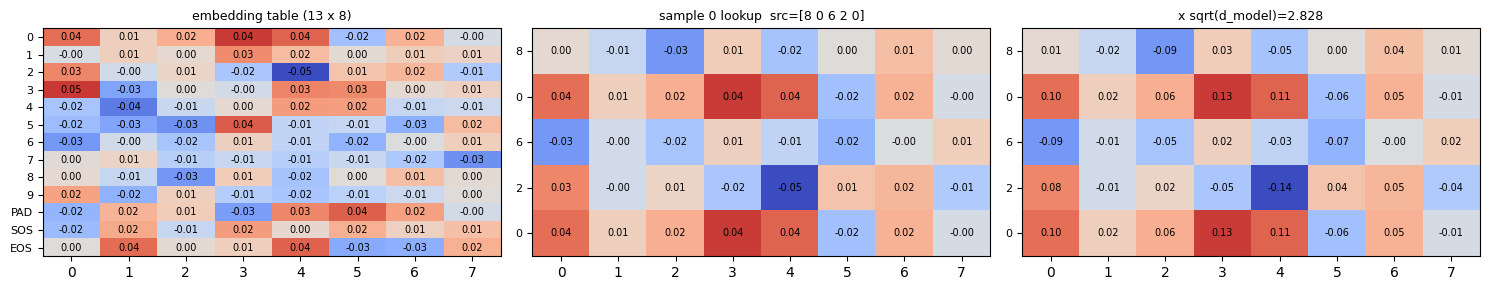

In [4]:
src = BATCHES[0][0]                       # (2, 5)
E = model.embedding.weight
emb = E[src]                              # (2, 5, 8)
emb_scaled = emb * np.sqrt(D_MODEL)

fig, ax = plt.subplots(1, 3, figsize=(15, 3))
heat(E, yl=[TOK[i] for i in range(VOCAB_SIZE)], title="embedding table (13 x 8)", ax=ax[0], fmt="{:.2f}")
heat(emb[0], yl=[TOK[t] for t in src[0]], title=f"sample 0 lookup  src={src[0]}", ax=ax[1])
heat(emb_scaled[0], yl=[TOK[t] for t in src[0]], title=f"x sqrt(d_model)={np.sqrt(D_MODEL):.3f}", ax=ax[2])
plt.tight_layout(); plt.show()
assert np.allclose(model.encoder.embedding.forward(src), emb)

## 4. Sinusoidal positional encoding

$$PE_{(pos,2i)}=\sin\!\Big(\frac{pos}{10000^{2i/d_{model}}}\Big)\qquad PE_{(pos,2i+1)}=\cos\!\Big(\frac{pos}{10000^{2i/d_{model}}}\Big)$$

Even columns use sine and odd columns use cosine. Each pair `(2i, 2i+1)` shares one frequency, and the frequencies get lower as `i` grows. The table is fixed: it has no learnable weights.

divisors 10000^(2i/d): [   1.   10.  100. 1000.]

angle = pos / divisor  (rows=pos, cols=pair i)
[[0.    0.    0.    0.   ]
 [1.    0.1   0.01  0.001]
 [2.    0.2   0.02  0.002]
 [3.    0.3   0.03  0.003]
 [4.    0.4   0.04  0.004]]

worked example pos=2, dim 0: sin(2/1)=0.9093 ; dim 1: cos(2/1)=-0.4161 ; dim 2: sin(2/10.00)=0.1987


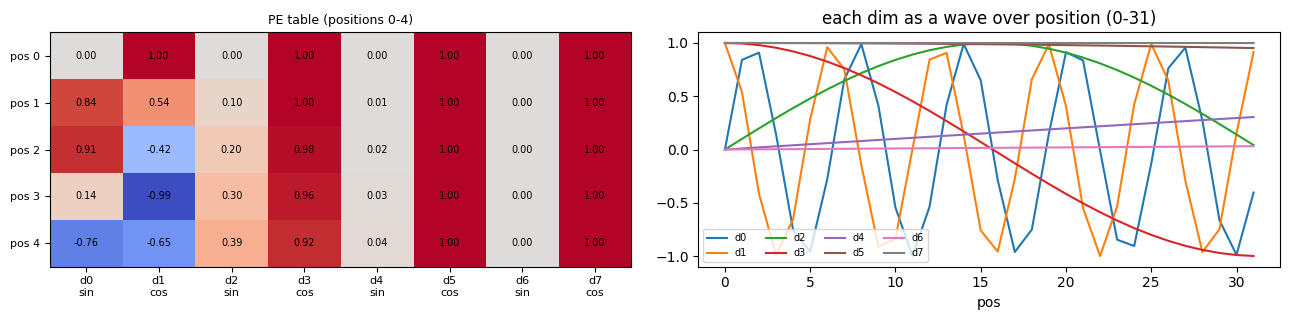

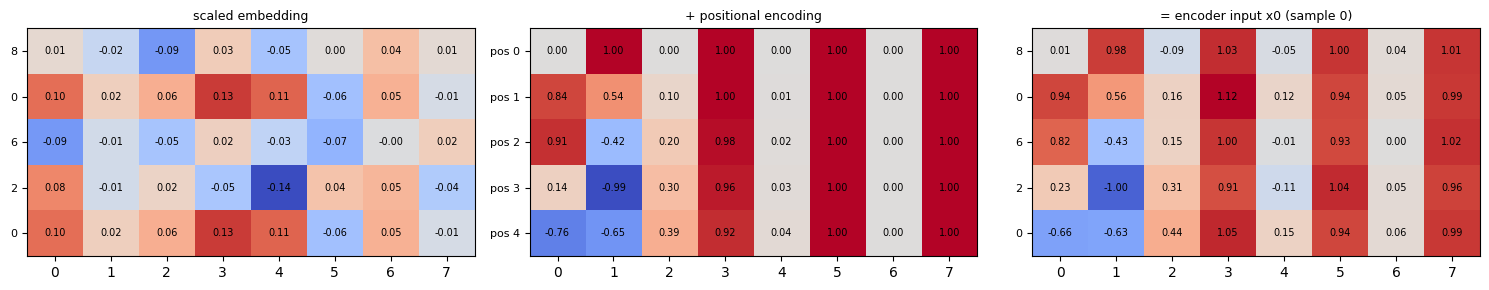

|PE[0]-PE[1]|=0.964   |PE[0]-PE[4]|=1.862   -> positions are distinguishable


In [5]:
L = src.shape[1]
pos = np.arange(L)[:, None]
i = np.arange(D_MODEL // 2)
div = 10000.0 ** (2 * i / D_MODEL)
print("divisors 10000^(2i/d):", div)
angle = pos / div                          # (L, 4)
PE = np.zeros((L, D_MODEL)); PE[:, 0::2] = np.sin(angle); PE[:, 1::2] = np.cos(angle)
assert np.allclose(PE, model.encoder.pos_enc.pe[:L])

print("\nangle = pos / divisor  (rows=pos, cols=pair i)"); print(angle)
print("\nworked example pos=2, dim 0: sin(2/1)=%.4f ; dim 1: cos(2/1)=%.4f ; dim 2: sin(2/%.2f)=%.4f"
      % (np.sin(2), np.cos(2), div[1], np.sin(2/div[1])))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.3))
heat(PE, xl=[f"d{k}\n{'sin' if k%2==0 else 'cos'}" for k in range(D_MODEL)], yl=[f"pos {p}" for p in range(L)],
     title="PE table (positions 0-4)", ax=ax[0], vmax=1)
P = model.encoder.pos_enc.pe[:32]
for k in range(D_MODEL):
    ax[1].plot(P[:, k], label=f"d{k}")
ax[1].set_title("each dim as a wave over position (0-31)"); ax[1].set_xlabel("pos"); ax[1].legend(ncol=4, fontsize=7)
plt.tight_layout(); plt.show()

# addition
x0 = emb_scaled + PE                       # broadcasts over batch
fig, ax = plt.subplots(1, 3, figsize=(15, 3))
heat(emb_scaled[0], yl=[TOK[t] for t in src[0]], title="scaled embedding", ax=ax[0])
heat(PE, yl=[f"pos {p}" for p in range(L)], title="+ positional encoding", ax=ax[1])
heat(x0[0], yl=[TOK[t] for t in src[0]], title="= encoder input x0 (sample 0)", ax=ax[2])
plt.tight_layout(); plt.show()

# why it matters: identical digits at different positions now differ
d_same = np.linalg.norm(PE[0] - PE[1]); d_far = np.linalg.norm(PE[0] - PE[4])
print(f"|PE[0]-PE[1]|={d_same:.3f}   |PE[0]-PE[4]|={d_far:.3f}   -> positions are distinguishable")

## 5. Scaled dot-product attention (single head, by hand)

$$\text{Attention}(Q,K,V)=\text{softmax}\!\Big(\frac{QK^\top}{\sqrt{d_k}}\Big)V$$

First we do it with **one head spanning all 8 dims** to see the pure mechanism. Sample 0, encoder self-attention, using the first encoder layer's Q/K/V projections.

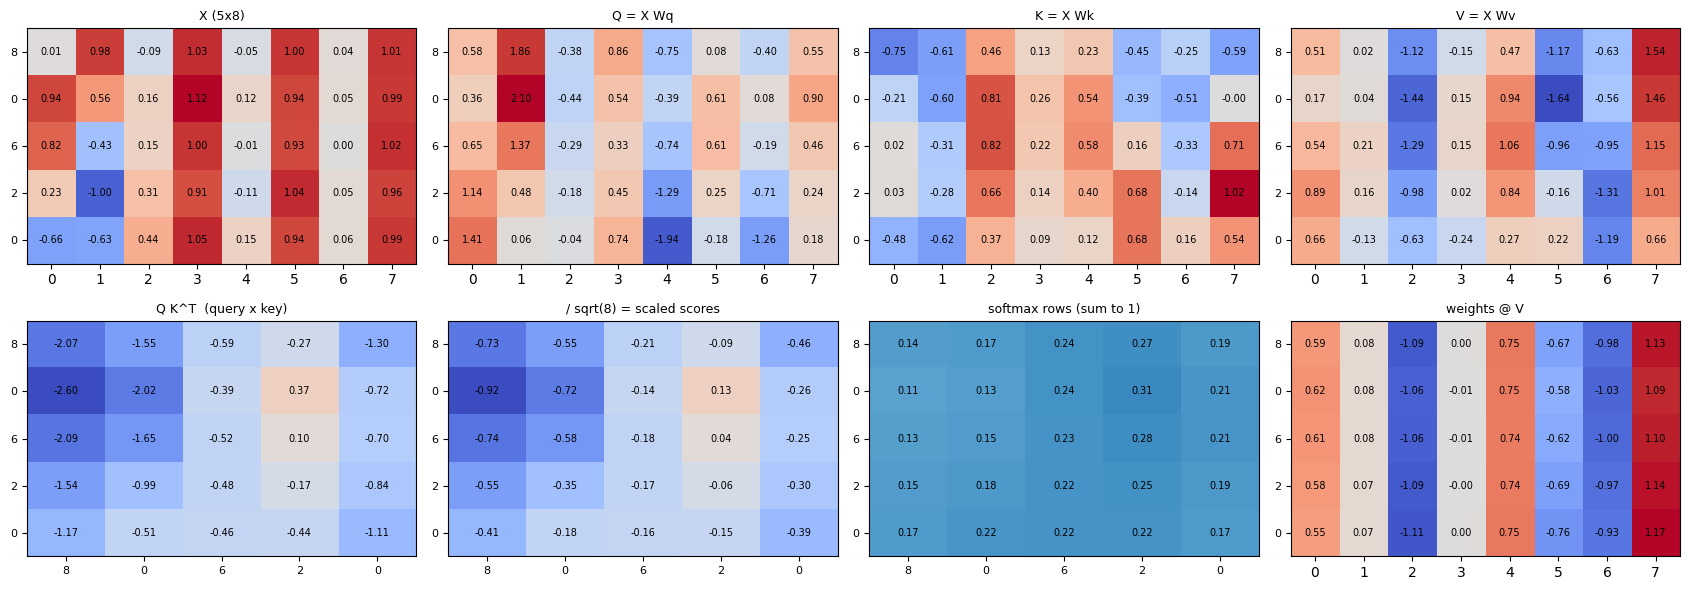

row sums of attention weights: [1. 1. 1. 1. 1.]

score[0,1] = q0 . k1 / sqrt(d) = -1.5483 / 2.828 = -0.5474
output[0] = sum_j w[0,j] * V[j] = [ 0.59   0.08  -1.087  0.     0.752 -0.674 -0.98   1.129]


In [6]:
enc_layer = model.encoder.layers[0]
mha = enc_layer.mha
X = x0[0]                                   # (5, 8)

Q = X @ mha.W_q.W + mha.W_q.b
K = X @ mha.W_k.W + mha.W_k.b
V = X @ mha.W_v.W + mha.W_v.b
scores_raw = Q @ K.T
scores = scores_raw / np.sqrt(D_MODEL)
W_att = softmax(scores)
out = W_att @ V

lab = [TOK[t] for t in src[0]]
fig, ax = plt.subplots(2, 4, figsize=(17, 6))
heat(X, yl=lab, title="X (5x8)", ax=ax[0, 0])
heat(Q, yl=lab, title="Q = X Wq", ax=ax[0, 1])
heat(K, yl=lab, title="K = X Wk", ax=ax[0, 2])
heat(V, yl=lab, title="V = X Wv", ax=ax[0, 3])
heat(scores_raw, lab, lab, "Q K^T  (query x key)", ax[1, 0])
heat(scores, lab, lab, f"/ sqrt({D_MODEL}) = scaled scores", ax[1, 1])
heat(W_att, lab, lab, "softmax rows (sum to 1)", ax[1, 2], vmax=1, cmap="Blues")
heat(out, yl=lab, title="weights @ V", ax=ax[1, 3])
plt.tight_layout(); plt.show()
print("row sums of attention weights:", W_att.sum(-1))

# worked single cell
print(f"\nscore[0,1] = q0 . k1 / sqrt(d) = {Q[0] @ K[1]:.4f} / {np.sqrt(D_MODEL):.3f} = {Q[0] @ K[1] / np.sqrt(D_MODEL):.4f}")
print(f"output[0] = sum_j w[0,j] * V[j] = {out[0]}")

Why divide by $\sqrt{d_k}$? Dot products of random vectors have variance proportional to $d_k$. Without the scaling, large scores push softmax into a near one-hot regime with vanishing gradients.

In [7]:
rng = np.random.default_rng(1)
for d in (4, 64, 512):
    q, k = rng.standard_normal((2, 2000, d))
    s = (q * k).sum(-1)
    print(f"d_k={d:4d}  std(q.k)={s.std():7.2f}   std after /sqrt(d_k)={(s/np.sqrt(d)).std():.2f}")

d_k=   4  std(q.k)=   2.01   std after /sqrt(d_k)=1.01
d_k=  64  std(q.k)=   7.98   std after /sqrt(d_k)=1.00
d_k= 512  std(q.k)=  22.35   std after /sqrt(d_k)=0.99


## 6. Multi-head attention

Instead of one 8-dim attention, split `Q, K, V` into **2 heads of 4 dims**. Each head attends independently (so heads can learn different patterns), the head outputs are concatenated, and `W_o` mixes them.

`(5, 8)` -> reshape `(5, 2, 4)` -> swap axes `(2, 5, 4)`.

Q: (5, 8) -> heads: (2, 5, 4)
head 0 gets dims 0-3, head 1 gets dims 4-7 of every token:
 Q[0] = [ 0.576  1.864 -0.377  0.864 -0.747  0.081 -0.398  0.546]
 Qh[0,0] = [ 0.576  1.864 -0.377  0.864]  Qh[1,0] = [-0.747  0.081 -0.398  0.546]


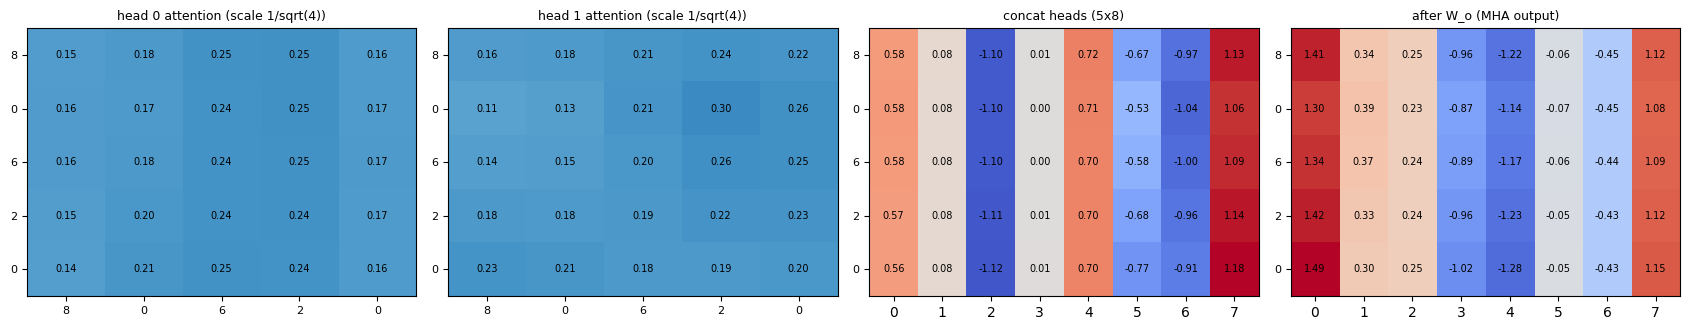

manual multi-head == MultiHeadAttention.forward  (verified)


In [8]:
def split_heads(M):                 # (n, 8) -> (h, n, d_k)
    return M.reshape(M.shape[0], N_HEADS, D_K).transpose(1, 0, 2)

Qh, Kh, Vh = split_heads(Q), split_heads(K), split_heads(V)
print("Q:", Q.shape, "-> heads:", Qh.shape)
print("head 0 gets dims 0-3, head 1 gets dims 4-7 of every token:")
print(" Q[0] =", Q[0]); print(" Qh[0,0] =", Qh[0, 0], " Qh[1,0] =", Qh[1, 0])

sc_h = Qh @ Kh.transpose(0, 2, 1) / np.sqrt(D_K)         # (2, 5, 5)
A_h = softmax(sc_h)
O_h = A_h @ Vh                                           # (2, 5, 4)
merged = O_h.transpose(1, 0, 2).reshape(5, D_MODEL)      # concat heads
mha_out = merged @ mha.W_o.W + mha.W_o.b

fig, ax = plt.subplots(1, 4, figsize=(17, 3.4))
for h in range(N_HEADS):
    heat(A_h[h], lab, lab, f"head {h} attention (scale 1/sqrt({D_K}))", ax[h], vmax=1, cmap="Blues")
heat(merged, yl=lab, title="concat heads (5x8)", ax=ax[2])
heat(mha_out, yl=lab, title="after W_o (MHA output)", ax=ax[3])
plt.tight_layout(); plt.show()

assert np.allclose(mha_out, mha.forward(x0, x0, x0)[0])
assert np.allclose(A_h, mha.last_weights[0])
print("manual multi-head == MultiHeadAttention.forward  (verified)")

## 7. Full encoder layer (post-LN)

```
h   = MHA(x, x, x)
y   = LayerNorm(x + h)         # residual + norm
f   = FFN(y) = W2 relu(W1 y)   # position-wise, 8 -> 16 -> 8
out = LayerNorm(y + f)
```

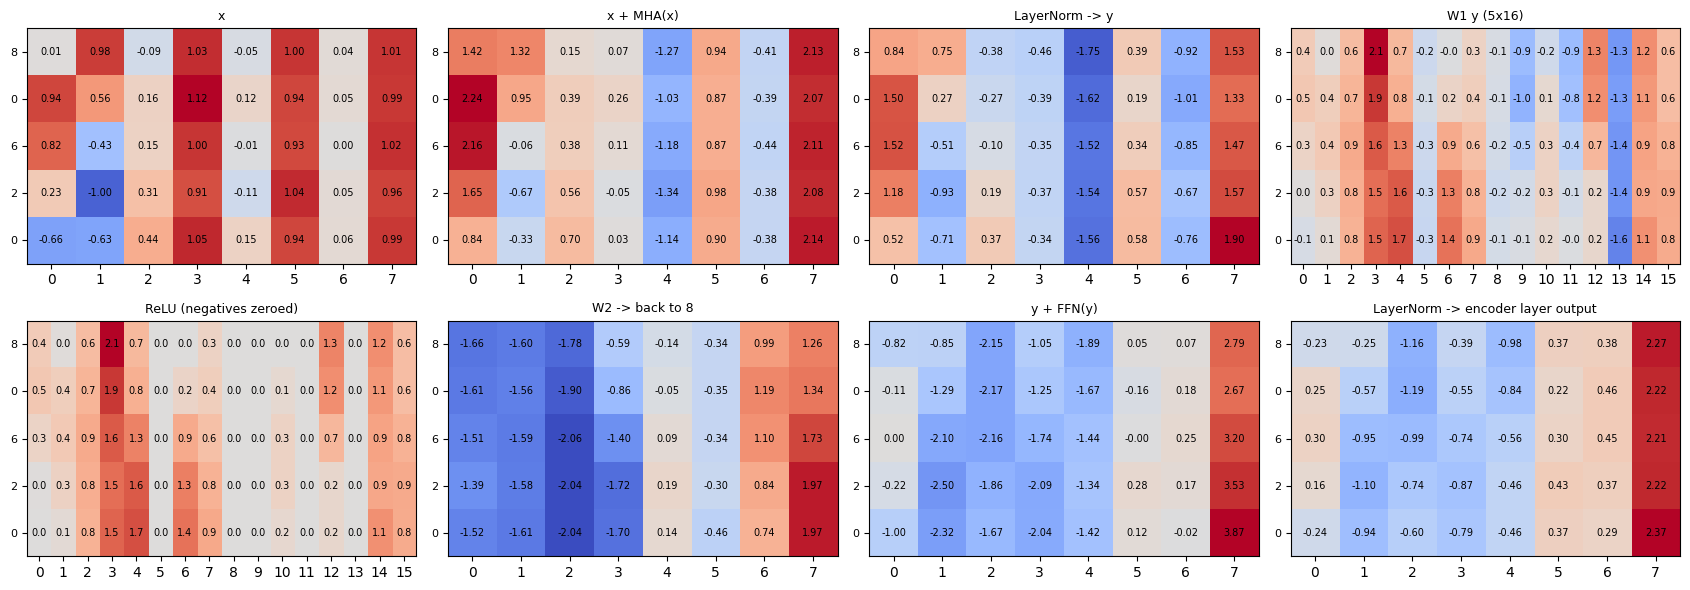

LayerNorm check: per-token mean ~0, var ~1 -> [ 0. -0.  0.  0. -0.] [1. 1. 1. 1. 1.]
manual encoder layer == Encoder.forward (verified).  encoder output ('memory') shape: (2, 5, 8)


In [9]:
def ln(layer, x):
    m, v = x.mean(-1, keepdims=True), x.var(-1, keepdims=True)
    return layer.gamma * (x - m) / np.sqrt(v + layer.eps) + layer.beta

h = mha_out
res1 = X + h
y = ln(enc_layer.ln_1, res1)
ffn = enc_layer.ffn
h_pre = y @ ffn.W_1.W + ffn.W_1.b
h_act = np.maximum(h_pre, 0)
f = h_act @ ffn.W_2.W + ffn.W_2.b
res2 = y + f
enc_out0 = ln(enc_layer.ln_2, res2)

fig, ax = plt.subplots(2, 4, figsize=(17, 6))
heat(X, yl=lab, title="x", ax=ax[0, 0]); heat(res1, yl=lab, title="x + MHA(x)", ax=ax[0, 1])
heat(y, yl=lab, title="LayerNorm -> y", ax=ax[0, 2])
heat(h_pre, yl=lab, title="W1 y (5x16)", ax=ax[0, 3], fmt="{:.1f}")
heat(h_act, yl=lab, title="ReLU (negatives zeroed)", ax=ax[1, 0], fmt="{:.1f}")
heat(f, yl=lab, title="W2 -> back to 8", ax=ax[1, 1]); heat(res2, yl=lab, title="y + FFN(y)", ax=ax[1, 2])
heat(enc_out0, yl=lab, title="LayerNorm -> encoder layer output", ax=ax[1, 3])
plt.tight_layout(); plt.show()
print("LayerNorm check: per-token mean ~0, var ~1 ->", y.mean(-1).round(6), y.var(-1).round(3))

enc_out = model.encoder.forward(src)
assert np.allclose(enc_out0, enc_out[0])
print("manual encoder layer == Encoder.forward (verified).  encoder output ('memory') shape:", enc_out.shape)

## 8. Decoder layer

The decoder has three sub-layers, each with residual + LayerNorm:

1. **Masked self-attention**: position *t* may only look at positions <= *t* (causal mask), so the model cannot peek at the answer.
2. **Cross-attention**: **queries come from the decoder, keys and values come from the encoder output**. This is how the decoder reads the source digits.
3. **FFN**.

Then a tied output projection `x @ E^T` (it reuses the embedding matrix) turns `(6, 8)` into logits over the 13 tokens.

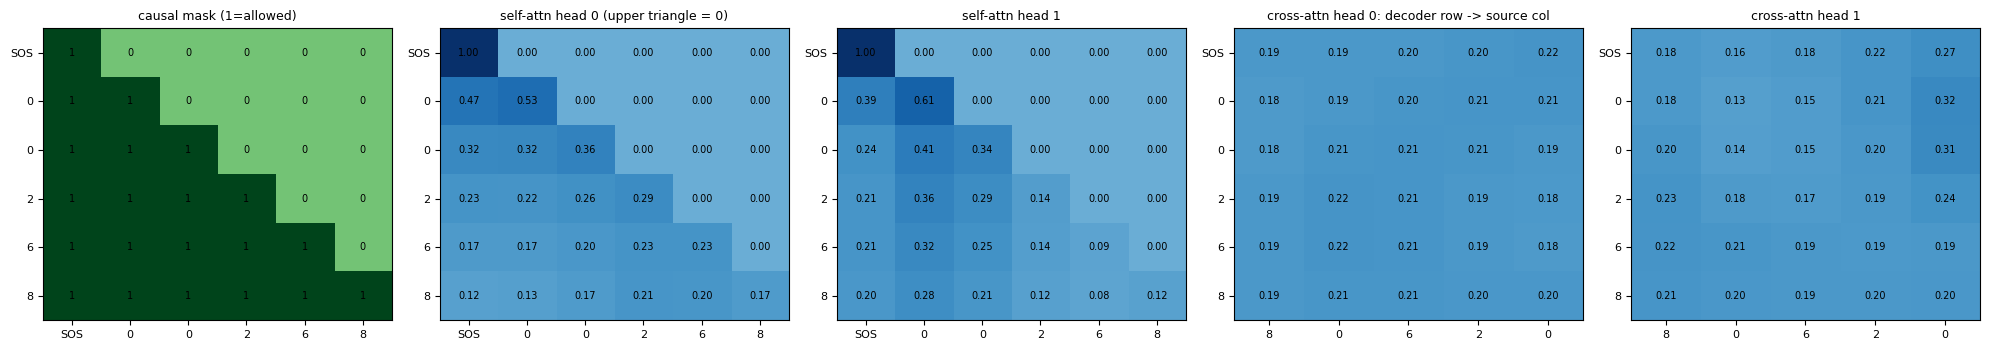

manual decoder == Decoder.forward (verified).  logits shape: (2, 6, 13)


In [10]:
dec_in = BATCHES[0][1]; dec_tgt = BATCHES[0][2]
dlab = [TOK[t] for t in dec_in[0]]
n_q = dec_in.shape[1]
causal = np.tril(np.ones((n_q, n_q), dtype=bool))

dx = E[dec_in] * np.sqrt(D_MODEL) + model.decoder.pos_enc.pe[:n_q]     # (2, 6, 8)
dl = model.decoder.layers[0]

def mha_manual(m, q_in, kv_in, mask=None):
    Q_, K_, V_ = (q_in @ m.W_q.W + m.W_q.b), (kv_in @ m.W_k.W + m.W_k.b), (kv_in @ m.W_v.W + m.W_v.b)
    sp = lambda M: M.reshape(M.shape[0], N_HEADS, D_K).transpose(1, 0, 2)
    s = sp(Q_) @ sp(K_).transpose(0, 2, 1) / np.sqrt(D_K)
    if mask is not None: s = np.where(mask, s, -np.inf)
    a = softmax(s)
    o = (a @ sp(V_)).transpose(1, 0, 2).reshape(q_in.shape[0], D_MODEL)
    return o @ m.W_o.W + m.W_o.b, a

# 1. masked self-attention
sa, A_self = mha_manual(dl.mha_self, dx[0], dx[0], causal)
y1 = ln(dl.ln_1, dx[0] + sa)
# 2. cross attention (Q from decoder y1, K/V from encoder)
ca, A_cross = mha_manual(dl.mha_cross, y1, enc_out[0])
y2 = ln(dl.ln_2, y1 + ca)
# 3. FFN
fd = np.maximum(y2 @ dl.ffn.W_1.W + dl.ffn.W_1.b, 0) @ dl.ffn.W_2.W + dl.ffn.W_2.b
y3 = ln(dl.ln_3, y2 + fd)
logits0 = y3 @ E.T

fig, ax = plt.subplots(1, 5, figsize=(20, 3.6))
heat(causal.astype(float), dlab, dlab, "causal mask (1=allowed)", ax[0], fmt="{:.0f}", vmax=1, cmap="Greens")
heat(A_self[0], dlab, dlab, "self-attn head 0 (upper triangle = 0)", ax[1], vmax=1, cmap="Blues")
heat(A_self[1], dlab, dlab, "self-attn head 1", ax[2], vmax=1, cmap="Blues")
heat(A_cross[0], lab, dlab, "cross-attn head 0: decoder row -> source col", ax[3], vmax=1, cmap="Blues")
heat(A_cross[1], lab, dlab, "cross-attn head 1", ax[4], vmax=1, cmap="Blues")
plt.tight_layout(); plt.show()

assert np.allclose(A_self[:, 0, 1:], 0)       # position 0 sees only itself; masked entries are exactly 0
dec_logits = model.decoder.forward(dec_in, enc_out)
assert np.allclose(logits0, dec_logits[0])
print("manual decoder == Decoder.forward (verified).  logits shape:", dec_logits.shape)

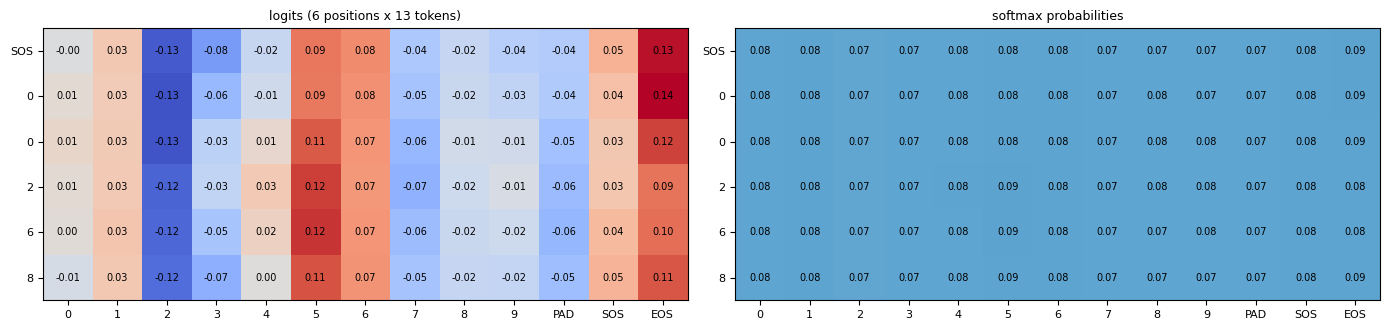

target  : ['0', '0', '2', '6', '8', 'EOS']
argmax  : ['EOS', 'EOS', 'EOS', '5', '5', '5']  (random weights, so this is not sorted yet)


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.4))
heat(logits0, [TOK[i] for i in range(VOCAB_SIZE)], dlab, "logits (6 positions x 13 tokens)", ax[0], fmt="{:.2f}")
heat(softmax(logits0), [TOK[i] for i in range(VOCAB_SIZE)], dlab, "softmax probabilities", ax[1], vmax=1, cmap="Blues", fmt="{:.2f}")
plt.tight_layout(); plt.show()
print("target  :", [TOK[t] for t in dec_tgt[0]])
print("argmax  :", [TOK[t] for t in logits0.argmax(-1)], " (random weights, so this is not sorted yet)")

## 9. The whole forward pass: how data moves

We wrap each sub-module and log the shape of every tensor it emits, then print the trace in execution order.

In [12]:
trace = []
def tap(obj, name, method="forward"):
    f = getattr(obj, method)
    def wrapped(*a, **k):
        r = f(*a, **k)
        trace.append((name, tuple(np.shape(a[0])), tuple(np.shape(r))))
        return r
    setattr(obj, method, wrapped)

tap(model.encoder.embedding, "ENC embedding lookup")
tap(model.encoder.pos_enc, "ENC + positional encoding")
el = model.encoder.layers[0]
for nm, o in [("ENC L0 multi-head self-attn", el.mha), ("ENC L0 LayerNorm 1", el.ln_1),
              ("ENC L0 feed-forward", el.ffn), ("ENC L0 LayerNorm 2", el.ln_2)]:
    tap(o, nm)
dl_ = model.decoder.layers[0]
tap(model.decoder.pos_enc, "DEC + positional encoding")
for nm, o in [("DEC L0 masked self-attn", dl_.mha_self), ("DEC L0 LayerNorm 1", dl_.ln_1),
              ("DEC L0 cross-attn (Q=dec, K/V=enc)", dl_.mha_cross), ("DEC L0 LayerNorm 2", dl_.ln_2),
              ("DEC L0 feed-forward", dl_.ffn), ("DEC L0 LayerNorm 3", dl_.ln_3),
              ("DEC tied output projection", model.decoder.output_projection)]:
    tap(o, nm)

s_, di_, dt_ = BATCHES[0]
logits = model.forward(s_, di_)
print(f"encoder tokens {s_.shape}, decoder tokens {di_.shape}\n")
print(f"{'stage':40s}{'in (first arg)':>18s}{'out':>18s}")
for n, i_, o_ in trace:
    print(f"{n:40s}{str(i_):>18s}{str(o_):>18s}")

encoder tokens (2, 5), decoder tokens (2, 6)

stage                                       in (first arg)               out
ENC embedding lookup                                (2, 5)         (2, 5, 8)
ENC + positional encoding                        (2, 5, 8)         (2, 5, 8)
ENC L0 multi-head self-attn                      (2, 5, 8)         (2, 5, 8)
ENC L0 LayerNorm 1                               (2, 5, 8)         (2, 5, 8)
ENC L0 feed-forward                              (2, 5, 8)         (2, 5, 8)
ENC L0 LayerNorm 2                               (2, 5, 8)         (2, 5, 8)
ENC embedding lookup                                (2, 6)         (2, 6, 8)
DEC + positional encoding                        (2, 6, 8)         (2, 6, 8)
DEC L0 masked self-attn                          (2, 6, 8)         (2, 6, 8)
DEC L0 LayerNorm 1                               (2, 6, 8)         (2, 6, 8)
DEC L0 cross-attn (Q=dec, K/V=enc)               (2, 6, 8)         (2, 6, 8)
DEC L0 LayerNorm 2            

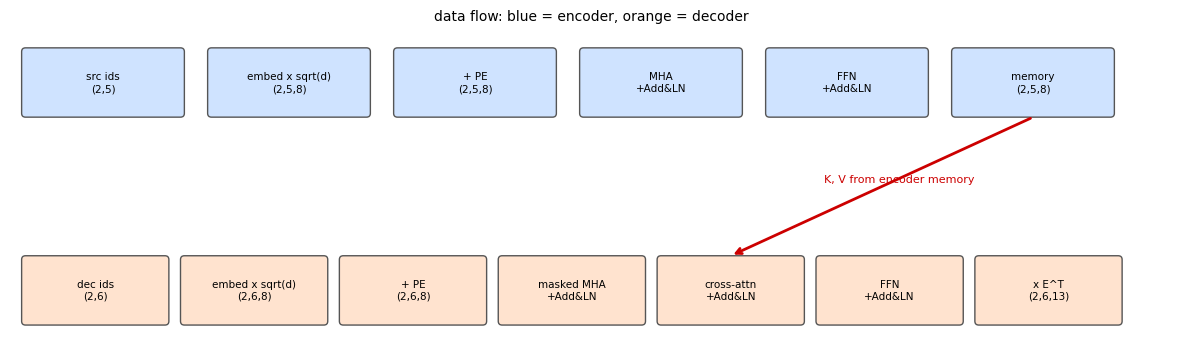

full Transformer.forward matches the hand-built pipeline for sample 0 (verified)


In [13]:
import matplotlib.patches as mp
fig, ax = plt.subplots(figsize=(15, 4.2)); ax.axis("off"); ax.set_xlim(0, 15); ax.set_ylim(0, 4.2)
def box(x, y, w, t, c):
    ax.add_patch(mp.FancyBboxPatch((x, y), w, 0.8, boxstyle="round,pad=0.05", fc=c, ec="#555"))
    ax.text(x + w/2, y + 0.4, t, ha="center", va="center", fontsize=7.5)
enc = ["src ids\n(2,5)", "embed x sqrt(d)\n(2,5,8)", "+ PE\n(2,5,8)", "MHA\n+Add&LN", "FFN\n+Add&LN", "memory\n(2,5,8)"]
dec = ["dec ids\n(2,6)", "embed x sqrt(d)\n(2,6,8)", "+ PE\n(2,6,8)", "masked MHA\n+Add&LN", "cross-attn\n+Add&LN", "FFN\n+Add&LN", "x E^T\n(2,6,13)"]
for k, t in enumerate(enc): box(0.2 + k*2.4, 3.1, 2.0, t, "#cfe3ff")
for k, t in enumerate(dec): box(0.2 + k*2.05, 0.4, 1.8, t, "#ffe3cf")
ax.annotate("", xy=(0.2 + 4*2.05 + 0.9, 1.25), xytext=(0.2 + 5*2.4 + 1.0, 3.05),
            arrowprops=dict(arrowstyle="->", color="#c00", lw=2))
ax.text(10.5, 2.2, "K, V from encoder memory", color="#c00", fontsize=8)
ax.set_title("data flow: blue = encoder, orange = decoder", fontsize=10)
plt.show()
assert np.allclose(logits[0], logits0)
print("full Transformer.forward matches the hand-built pipeline for sample 0 (verified)")

## 10. Loss, backward pass, optimizer: two training steps (1 epoch)

Per step: forward -> label-smoothed cross-entropy -> backward (gradients in every layer) -> Noam learning rate -> Adam update.

* Label smoothing (eps=0.1): the true class gets 0.9, and the other 12 classes share 0.1.
* Noam: $lr = d_{model}^{-0.5}\min(step^{-0.5},\ step\cdot warmup^{-1.5})$
* Adam: `m`, `v` moving averages with bias correction; `p -= lr * m_hat / (sqrt(v_hat)+eps)`.

In [14]:
# fresh, identical model so the section above doesn't affect training
np.random.seed(SEED)
model = Transformer(VOCAB_SIZE, D_MODEL, N_HEADS, D_FF, 1, 1, p_drop=0.0, max_len=32)
model.train()
opt = Adam(beta1=0.9, beta2=0.98, eps=1e-9)
snap = lambda: {n: p.copy() for p, g, n in model.params_and_grads()}
history = []

for step in range(1, N_STEPS * N_EPOCHS + 1):
    s_, di_, dt_ = BATCHES[(step - 1) % N_STEPS]
    print("=" * 78); print(f"STEP {step}   rows' encoder input:\n{s_}")
    before = snap()

    logits = model.forward(s_, di_)                                   # (2, 6, 13)
    loss, g_logits = cross_entropy_with_label_smoothing(
        logits, dt_, eps=EPS_LS, vocab_size=VOCAB_SIZE, pad_id=PAD_ID)
    probs = softmax(logits)
    p_true = np.take_along_axis(probs, dt_[..., None], -1)[..., 0]
    print(f"loss={loss:.4f}   P(correct token) per position:\n{p_true.round(3)}")
    print(f"uniform guess would give loss ~ ln(13)={np.log(13):.3f}")

    zero_grads(model)
    model.backward(g_logits)
    grads = {n: g.copy() for p, g, n in model.params_and_grads() if g is not None}

    lr = noam_lr(step, D_MODEL, WARMUP)
    opt.step(lr, model.params_and_grads())
    after = snap()
    print(f"lr (Noam, warmup={WARMUP}) = {lr:.5f}")
    history.append(dict(step=step, loss=loss, lr=lr, grads=grads, before=before, after=after, p_true=p_true, g_logits=g_logits))

STEP 1   rows' encoder input:
[[8 0 6 2 0]
 [5 9 7 7 7]]
loss=2.5682   P(correct token) per position:
[[0.077 0.077 0.067 0.082 0.075 0.085]
 [0.084 0.073 0.072 0.071 0.075 0.085]]
uniform guess would give loss ~ ln(13)=2.565
lr (Noam, warmup=4) = 0.04419
STEP 2   rows' encoder input:
[[7 5 1 8 4]
 [5 3 1 9 7]]
loss=2.5353   P(correct token) per position:
[[0.063 0.055 0.085 0.089 0.08  0.123]
 [0.063 0.055 0.085 0.089 0.082 0.123]]
uniform guess would give loss ~ ln(13)=2.565
lr (Noam, warmup=4) = 0.08839


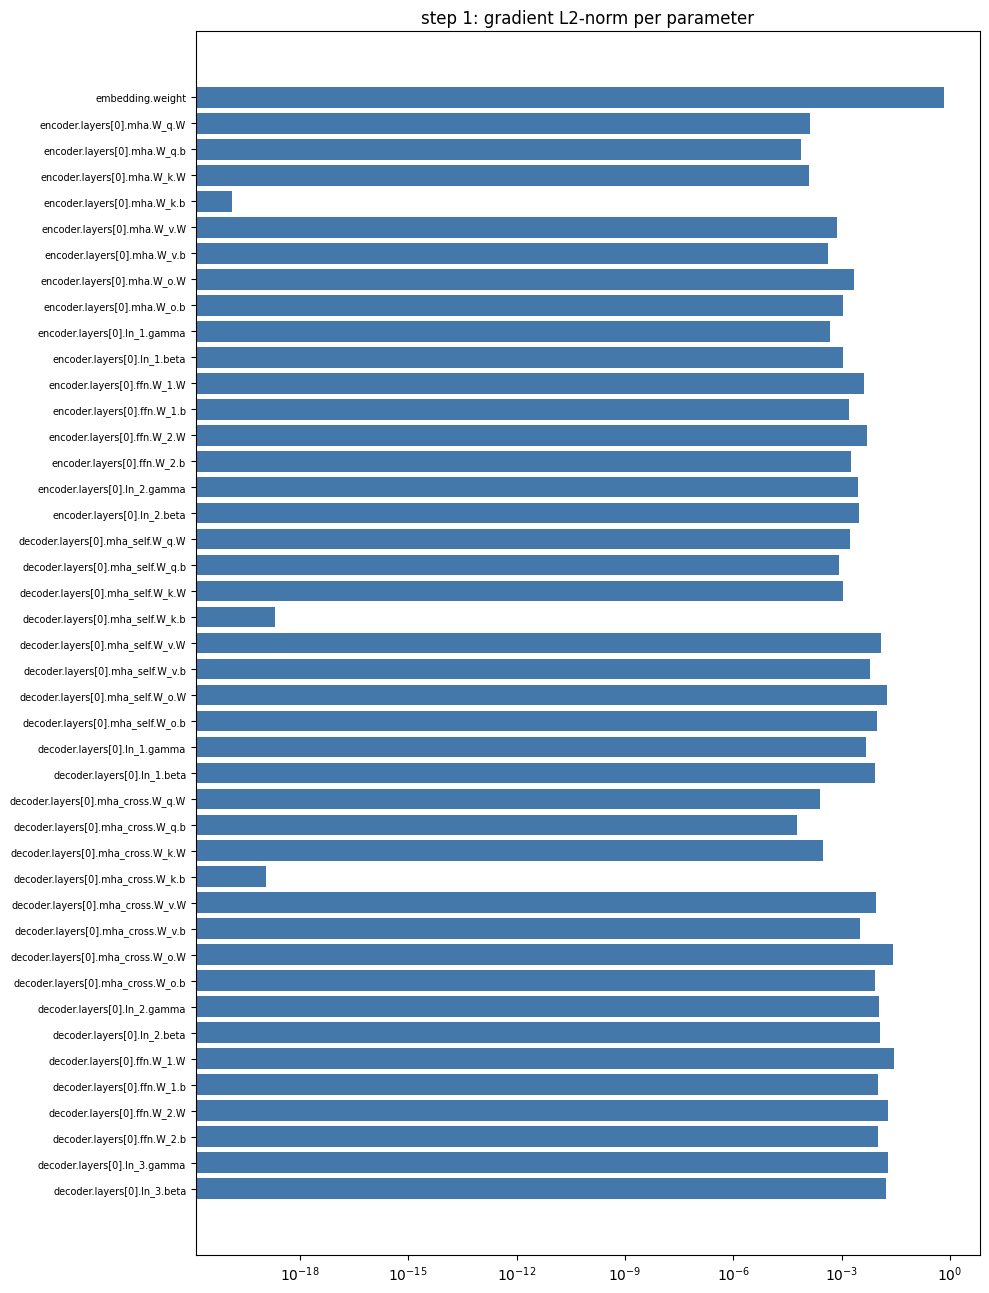

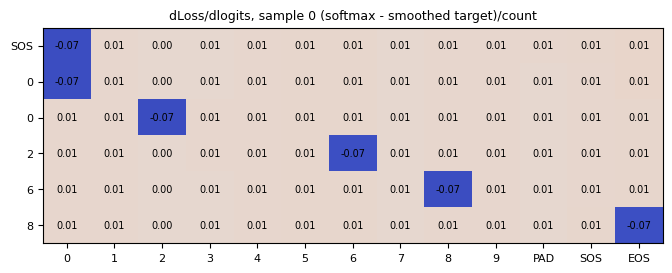

In [15]:
# Where does the gradient flow? Norm per parameter, step 1 (backward runs output -> input)
g = history[0]["grads"]
names = list(g)
norms = [np.linalg.norm(g[n]) for n in names]
fig, ax = plt.subplots(figsize=(10, 0.28 * len(names) + 1))
ax.barh(range(len(names)), norms, color="#4477aa"); ax.set_yticks(range(len(names)))
ax.set_yticklabels(names, fontsize=7); ax.invert_yaxis(); ax.set_xscale("log")
ax.set_title("step 1: gradient L2-norm per parameter"); plt.tight_layout(); plt.show()

gl = history[0]["g_logits"]
fig, ax = plt.subplots(figsize=(8, 2.8))
heat(gl[0], [TOK[i] for i in range(VOCAB_SIZE)], dlab, "dLoss/dlogits, sample 0 (softmax - smoothed target)/count", ax, fmt="{:.2f}")
plt.show()

parameter: encoder.layers[0].mha.W_q.W


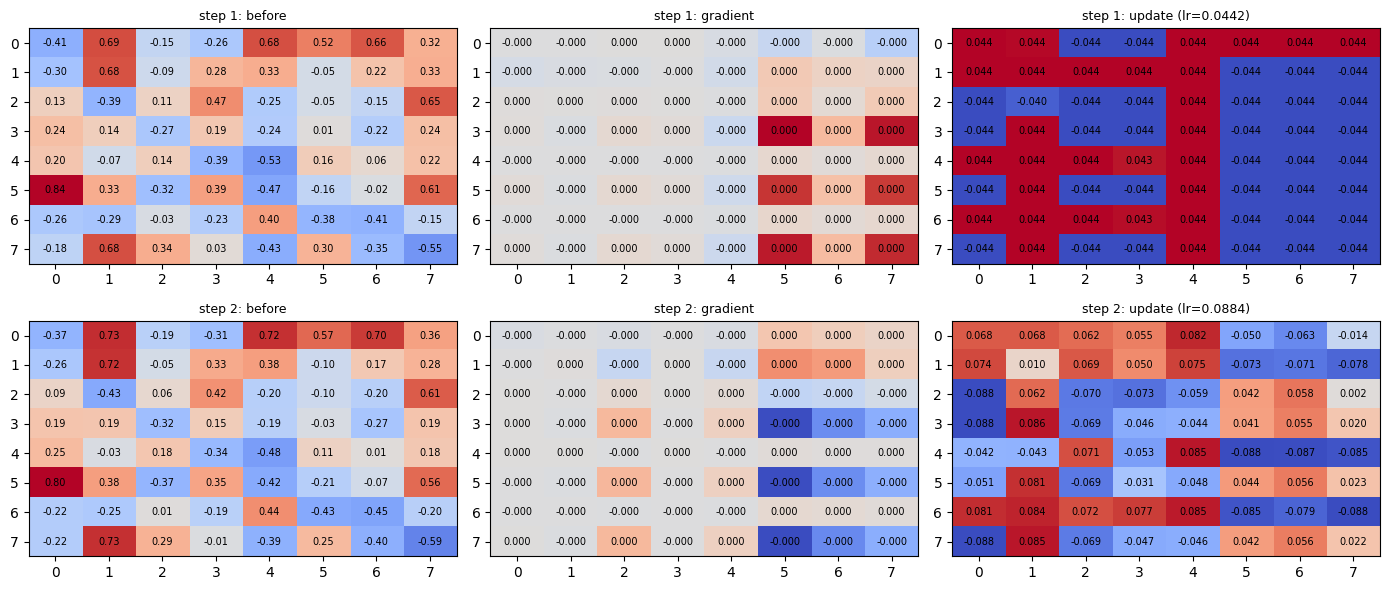

step-1 update == lr * g/(|g|+eps)? True


In [16]:
# Adam update on one concrete weight matrix: encoder W_q
key = [n for n in history[0]["grads"] if "W_q" in n and "enc" in n.lower()][0]
print("parameter:", key)
fig, ax = plt.subplots(2, 3, figsize=(14, 6))
for r, h in enumerate(history):
    heat(h["before"][key], title=f"step {h['step']}: before", ax=ax[r, 0], fmt="{:.2f}")
    heat(h["grads"][key], title=f"step {h['step']}: gradient", ax=ax[r, 1], fmt="{:.3f}")
    heat(h["after"][key] - h["before"][key], title=f"step {h['step']}: update (lr={h['lr']:.4f})", ax=ax[r, 2], fmt="{:.3f}")
plt.tight_layout(); plt.show()

# Adam first step by hand for 1 element: m_hat/sqrt(v_hat) = g/|g| -> update = lr * sign(g)
h0 = history[0]; gg = h0["grads"][key]
print("step-1 update == lr * g/(|g|+eps)?", np.allclose(h0["before"][key] - h0["after"][key], h0["lr"] * gg / (np.abs(gg) + 1e-9)))

In [17]:
# Re-evaluate both batches after the two updates (no dropout, so deterministic)
model.eval()
print(f"{'':10s}{'loss before':>14s}{'loss after':>14s}")
for k, h in enumerate(history):
    s_, di_, dt_ = BATCHES[k]
    l, _ = cross_entropy_with_label_smoothing(model.forward(s_, di_), dt_, eps=EPS_LS, vocab_size=VOCAB_SIZE, pad_id=PAD_ID)
    print(f"batch {k+1:<4d}{h['loss']:>14.4f}{l:>14.4f}")
print("\nWith 2 steps the model has barely moved; the point is the mechanics. Raise N_STEPS (and WARMUP) to watch it learn to sort.")

             loss before    loss after
batch 1           2.5682        2.5511
batch 2           2.5353        2.4052

With 2 steps the model has barely moved; the point is the mechanics. Raise N_STEPS (and WARMUP) to watch it learn to sort.


## Summary

```
src ids -> Embedding x sqrt(d) -> + sinusoidal PE -> [MHA -> Add&LN -> FFN -> Add&LN] -> memory
                                                                                         |  (K, V)
dec ids -> Embedding x sqrt(d) -> + PE -> [masked MHA -> Add&LN -> cross-attn(Q=dec) -> Add&LN -> FFN -> Add&LN]
        -> x E^T -> logits -> label-smoothed CE -> backward -> Noam lr -> Adam
```